In [10]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
from glob import glob
import numpy as np
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import gsw
import cmocean.cm as cmo
import pickle

from utils import get_shelf_edge, make_map, subplots_structure, add_observation_locations
from geostrophic_utils import (_plot_single_day, get_angle, compute_geostrophic_velocity,
                              _plot_one_track, plot_eddies, daily_geostrophic_current,
                              build_transect, ultimate_plot_one_track, plot_timeseries2)

from geostrophic_utils import load_satellites, plot_4days_tracks,  get_uv2

In [11]:
import matplotlib as mpl

mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12

In [12]:
import dask
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=5) #number of cores
client = Client(cluster) # go check dask dashboard

In [13]:
# extent =[360-47.5, 360-37.5, -28, -20.62] # max lat fits the gebco data I have for sheld egde contour
extent = [-45, -41, -26, -22]
zoomed_extent= [-45, -39, -27, -22]

# set relative path to the source file
datadir = './../data/aviso_alongtracks'
savedir = './../figures/aviso/alongtracks/sanagu2022/march_evolution'

timerange = [pd.to_datetime('2022-03-01'), 
             pd.to_datetime('2022-04-01')]

In [14]:
# loading netcdf files (gridded SSH from aviso, mesoscale eddy ATLAS and 
# alongtrack from several satellites

# loading gridded aviso ssh
ds_aviso = xr.open_dataset(f"{datadir}/../dataset-duacs-nrt-global-merged-allsat-phy-l4_20220101_20220401.nc")

# loading eddies
ds_locs = xr.open_dataset(f"{datadir}/../eddies_sanagu2022_daily.nc")

fnames = glob(f"{datadir}/*")
satellite = [fname.split("_")[3] for fname in fnames]
usatellites = list(np.unique(satellite))

In [15]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [16]:
# loading ARGO profiles locations
ds_argo = xr.open_dataset('../data/argo/argo_profiles_all.nc')

# loading SANAGU dataset
locs = pd.read_csv(f"../data/locations.csv", index_col=0)

In [8]:
days = [pd.to_datetime('2022-02-16'),
        pd.to_datetime('2022-02-21'), 
        pd.to_datetime('2022-03-07'), 
        pd.to_datetime('2022-03-27')]

ds_list = load_satellites(days, datadir)

tracks = {
 '2022-02-16': {
    'alg': {'track': [645], 'cycle': [158], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False},
    'c2n': {'track': [439], 'cycle': [222], 'inclination': 'positive', 'data': None, 'fix': False, 'fix_stickplot': False},
    'h2b': {'track': [57], 'cycle': [87], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False},
    },
 '2022-02-21': {
    'h2b': {'track': [195], 'cycle': [87], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False},
    's3a': {'track': [332], 'cycle': [82], 'inclination': 'positive', 'data': None, 'fix': False, 'fix_stickplot': False},
    's6a': {'track': [126], 'cycle': [47], 'inclination': 'negative', 'data': None, 'fix': True, 'fix_stickplot': False}
    },
 '2022-03-07': {
      's3b': {'track': [446], 'cycle': [63], 'inclination': 'positive', 'data': None, 'fix': False, 'fix_stickplot': False},
      'alg': {'track': [187], 'cycle': [159], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False},
      'c2n': {'track': [265], 'cycle': [223], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False}
     },
 '2022-03-27': {
      's3b': {'track': [233], 'cycle': [64], 'inclination': 'negative', 'fix': False, 'fix_stickplot': True},
      's6a': {'track': [239], 'cycle': [50], 'inclination': 'positive', 'fix': True, 'fix_stickplot': True}
 }
}

# adding information based on the dataset itself, like inclination angle and the dataset
for t,day in enumerate(tracks):
    ds = ds_list[str(t)]

    for k in tracks[day]:
        dsi = ds[k]

        for track,cycle in zip(tracks[day][k]['track'], tracks[day][k]['cycle']):
            dsplot = dsi.where(dsi['track'] == track, drop=True)
            dsplot = dsplot.where(dsplot['cycle'] == cycle, drop=True)
            
            # identify the angle of the track relative to the geographical north
            theta = get_angle(dsplot['longitude'].values, dsplot['latitude'].values)

            tracks[day][k]['data'] = dsplot
            tracks[day][k]['theta'] = np.abs(theta) if tracks[day][k]['inclination'] == 'positive' else theta

100%|██████████| 8/8 [00:11<00:00,  1.38s/it]


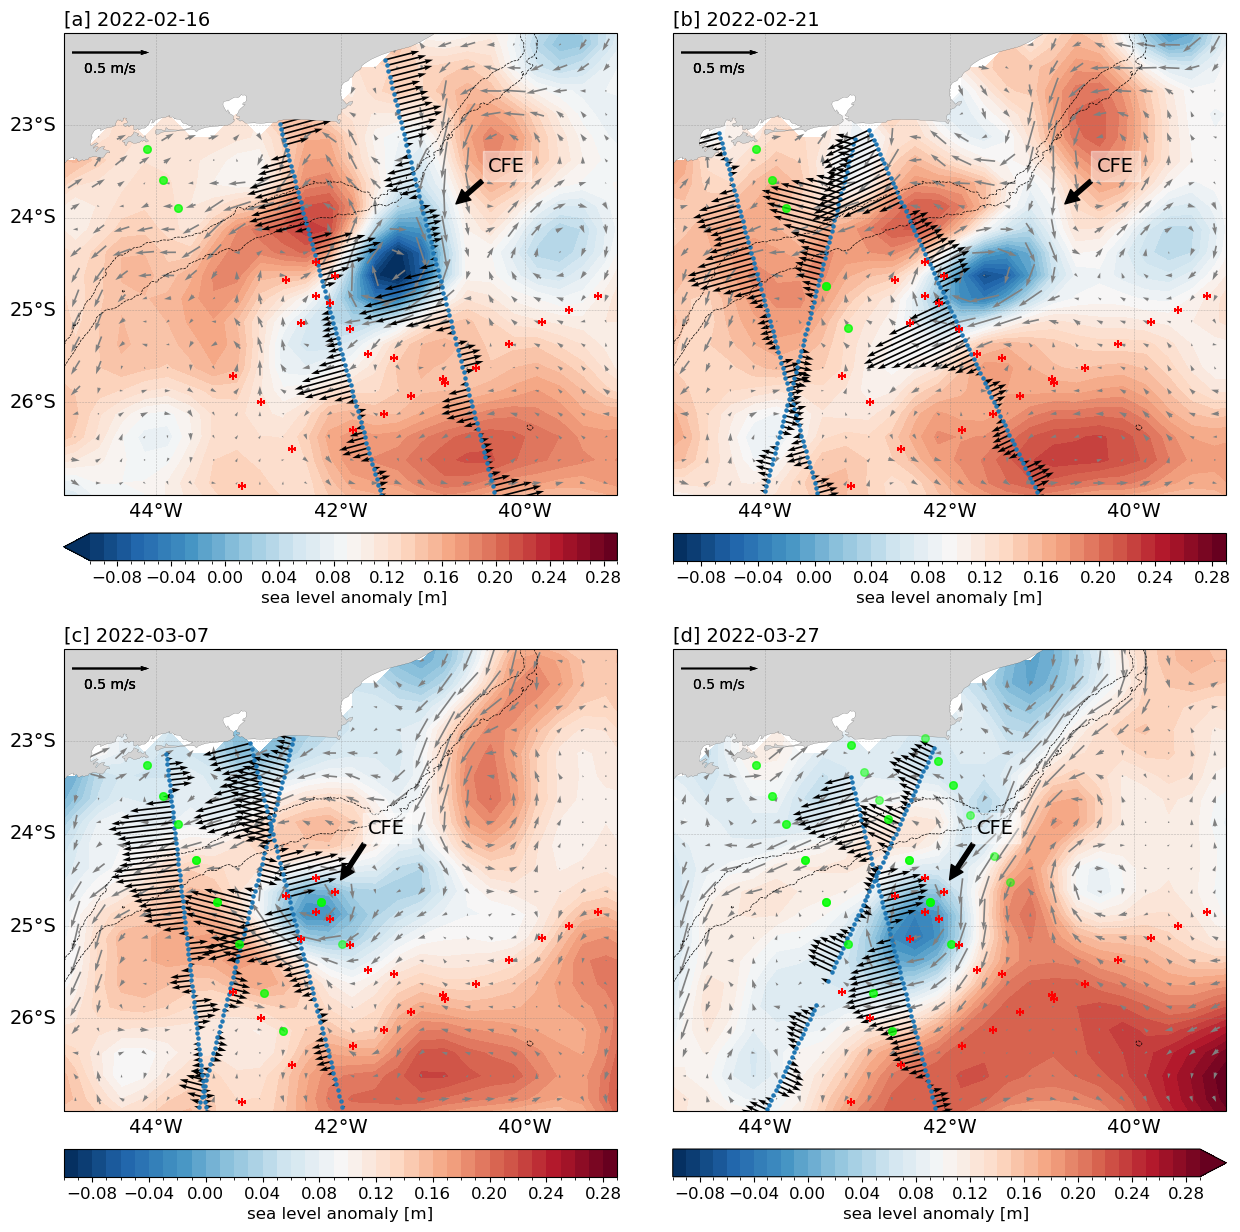

In [18]:
import cmocean as cmo

zoomed_extent= [-45, -39, -27, -22]

transect = build_transect(['2022-03-11', '2022-03-27'])

# selecting a zoomed region to plot the SLA from AVISO
ds_aviso_plot = ds_aviso.sel(longitude=slice(zoomed_extent[0]-0.5, zoomed_extent[1]+0.5),
                              latitude=slice(zoomed_extent[2]-0.5, zoomed_extent[3]+0.5))

days = list(tracks.keys())

# creating a letters list
letters = '[a] [b] [c] [d]'.split(' ')

fig,axes = subplots_structure(2, 2, (15,18), 4)

for n in range(4):
    drawlineleft = True if n in [0,2] else False
    day = days[n]
    t = f"{letters[n]} {day}"
    ax = axes[n]

    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1, drawlineleft=drawlineleft)
    ax.set_extent(zoomed_extent)

    bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    locs_plot = locs[locs['time'].astype('datetime64[ns]') <= pd.to_datetime(day)]
    ax.scatter(locs_plot['lon'], locs_plot['lat'], s=30, zorder=11, alpha=.5, marker='o', color='lime')
    
    ds_argo_plot = ds_argo.where(ds_argo['TIME'] <= pd.to_datetime(day), drop=True)
    ax.scatter(ds_argo['LONGITUDE'], ds_argo['LATITUDE'], color='r', zorder=11, s=30, marker='+')

    _plot_single_day(ax, day, tracks, ds_aviso=ds_aviso_plot, adt=True,
                     transect=None,
                     cbar_kwargs={'orientation': 'horizontal', 'location': 'bottom','pad': .05},
                     contourf_kwargs={"levels": np.arange(-0.1, 0.3, 0.01), 
                                      "cmap": "RdBu_r"}
                    )
    ax.set_title('')
    ax.set_title(t, loc='left', fontsize=14)
    
plt.subplots_adjust(hspace=0.0, wspace=.1)

fig.patch.set_alpha(1.0)
plt.subplots_adjust(hspace=-.2)

# despite CFE and AgR on the first two maps
for n in range(2):
    t = axes[n].annotate("CFE",xy=(-40.75, -23.85), xytext=(-40.2, -23.5),
             arrowprops={"width": 3, "headwidth": 10, "headlength": 10, 'color': 'k'},
             horizontalalignment="center", fontsize=14)
    t.set_bbox(dict(facecolor='white', alpha=0.4, edgecolor='white'))
    
    # t = axes[n].annotate("AE",xy=(-40., -26), xytext=(-39.5, -25.5),
    #              arrowprops={"width": 3, "headwidth": 10, "headlength": 10, 'color': 'k'},
    #              horizontalalignment="center", fontsize=14)
    # t.set_bbox(dict(facecolor='white', alpha=0.4, edgecolor='white'))

# the third map has different location
t = axes[2].annotate("CFE",xy=(-42., -24.5), xytext=(-41.5, -24),
         arrowprops={"width": 3, "headwidth": 10, "headlength": 10, 'color': 'k'},
         horizontalalignment="center", fontsize=14)
t.set_bbox(dict(facecolor='white', alpha=0.4, edgecolor='white'))

t = axes[3].annotate("CFE",xy=(-42., -24.5), xytext=(-41.5, -24),
         arrowprops={"width": 3, "headwidth": 10, "headlength": 10, 'color': 'k'},
         horizontalalignment="center", fontsize=14)
t.set_bbox(dict(facecolor='white', alpha=0.4, edgecolor='white'))

# t = axes[2].annotate("AE",xy=(-41., -26.5), xytext=(-40.5, -26),
#              arrowprops={"width": 3, "headwidth": 10, "headlength": 10, 'color': 'k'},
#              horizontalalignment="center", fontsize=14)
# t.set_bbox(dict(facecolor='white', alpha=0.4, edgecolor='white'))

plt.savefig('../figures/manuscript/00_review_geostrophic_fields_with_ADT_new.png', bbox_inches="tight", dpi=300)

# Version with SST as contourf

For reviewer response.

In [18]:
def add_aviso(ax, ds_aviso, 
              quiver_kwargs={"scale": 10, "width": .003, "color": "gray"},
              contourf_kwargs={"levels": np.arange(-0.5, 0.5, 0.01), "cmap": "RdBu_r"},
              cbar_kwargs={'orientation': 'horizontal', 'location': 'bottom','pad': 0.03}):
    
    # add contour/contourf
    CS = ds_aviso.sla.plot.contour(ax=ax, 
                                   x='longitude', 
                                   y='latitude', 
                                   # levels=np.arange(0.3, 1., 0.05), 
                                   colors='gray', 
                                   linewidths=(.5), 
                                   kwargs=dict(inline=True))
    # _ = ds_aviso.sla.plot.contourf(ax=ax, 
    #                                x='longitude', 
    #                                y='latitude',
    #                                cbar_kwargs=cbar_kwargs,
    #                                **contourf_kwargs)
    # _.colorbar.set_label('sea level anomaly [m]', fontsize=12)
    
    # ax.clabel(CS)
    
    # add quiver
    ds_aviso.plot.quiver(ax=ax, 
                         x='longitude', 
                         y='latitude', 
                         u='ugos', 
                         v='vgos', **quiver_kwargs)
    
    return ax

################################################################################

def add_geostrophic_velocity(ax, dsplot, theta, fix, adt=False,
                             quiverkey=[-45, -22.5, 0.5, '0.5 m/s'],
                             quiverkey_kws=dict(labelpos='S', color='k', coordinates='data'),
                             quiver_kwargs=dict(scale=5000, width=.003, color='k')):
    
    # calculations
    lon, lat, ug, vg = compute_geostrophic_velocity(dsplot, theta, fix, adt)

    # plot
    q = ax.quiver(lon, lat, ug, vg, **quiver_kwargs)
    
    # add quiverkey
    if quiverkey != None:
        qk = ax.quiverkey(q,
                          quiverkey[0], # x position
                          quiverkey[1], # y position
                          quiverkey[2], # unit 
                          quiverkey[3], # label
                          **quiverkey_kws).set_zorder(11)

    return ax

################################################################################

def _plot_single_day_sst(ax, day, tracks, adt=False, ds_aviso=None, ds_locs=None, 
                     cbar_kwargs={'orientation': 'horizontal', 'location': 'bottom','pad': 0.03},
                     contourf_kwargs={"levels": np.arange(-0.5, 0.5, 0.01), "cmap": "RdBu_r"},
                     colors=None, transect=None, shelf=None):
    
    from geostrophic_utils import add_track_scatter, add_transect
    
    # load shelf edge
    if shelf != None:
        ax.plot(shelf['lon'], shelf['lat'], c='white', ls='--')

    # plot background variable if available
    if ds_aviso:
        _ = add_aviso(ax, ds_aviso.sel(time=day), 
                      cbar_kwargs=cbar_kwargs, 
                      contourf_kwargs=contourf_kwargs,
                      quiver_kwargs={"scale": 10, "width": .003, "color": "gray", "add_guide": False})
               
    # plotting along track geostrophic
    for sat in tracks[day]:
        if colors:
            c = colors[sat]
        else:
            c = 'tab:blue'
            
        dsplot = tracks[day][sat]['data']
        theta = tracks[day][sat]['theta']
        fix = tracks[day][sat]['fix']

        # add geostrophic current over the map
        _ = add_geostrophic_velocity(ax, dsplot, theta, fix, adt=adt,
                                     quiverkey=[-44.5, -22.2, 0.5, '0.5 m/s'],
                                     quiver_kwargs={"scale": 3.6, "units": "width", 
                                                    "width": .003, "color": "k"})

        # add track scatter
        _ = add_track_scatter(ax, dsplot, color=c)
        
        if transect:
            _ = add_transect(ax, transect['lons'], transect['lats'])

In [21]:
dsst = xr.open_mfdataset("../data/AVHRR/*.nc")
dsst = dsst.where(dsst.quality_level > 3, drop=True)
ds_daily = dsst.resample(time='1D').mean()

In [22]:
ds_plot = (ds_daily.sea_surface_temperature - 273.15).sel(lon=slice(-47.5, -37.5), lat=slice(-20, -28), )

# find indexes for days of intereset
ind_time = []

# ds_plot = ds_plot.sel(time=[pd.to_datetime(x) for x in days])

# ind_time = [)[0].item() for x in days]

dic = {}
for x in days:
    i = np.where(ds_plot['time'].values == pd.to_datetime(x))[0].item()
    
    dic[x] = ds_plot.isel(time=slice(i-3, i+3)).mean(dim='time')

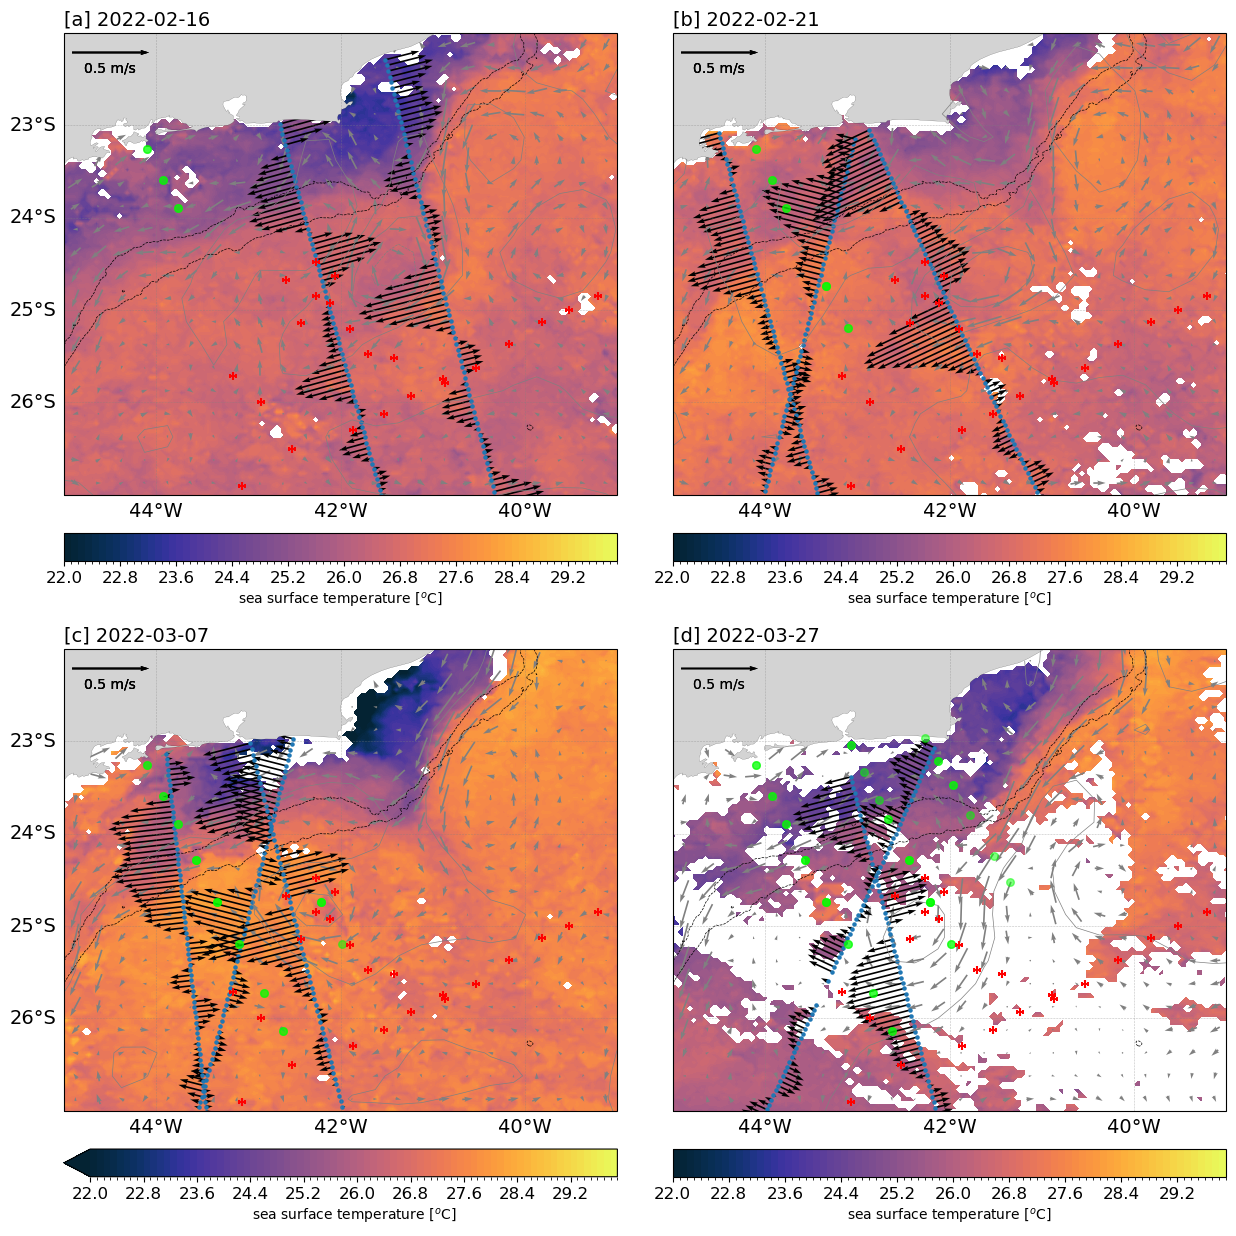

In [23]:
import cmocean as cmo

zoomed_extent= [-45, -39, -27, -22]

transect = build_transect(['2022-03-11', '2022-03-27'])

# selecting a zoomed region to plot the SLA from AVISO
ds_aviso_plot = ds_aviso.sel(longitude=slice(zoomed_extent[0]-0.5, zoomed_extent[1]+0.5),
                              latitude=slice(zoomed_extent[2]-0.5, zoomed_extent[3]+0.5))

days = list(tracks.keys())

# creating a letters list
letters = '[a] [b] [c] [d]'.split(' ')

fig,axes = subplots_structure(2, 2, (15,18), 4)

for n in range(4):
    drawlineleft = True if n in [0,2] else False
    day = days[n]
    t = f"{letters[n]} {day}"
    ax = axes[n]

    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1, drawlineleft=drawlineleft)
    ax.set_extent(zoomed_extent)

    bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    locs_plot = locs[locs['time'].astype('datetime64[ns]') <= pd.to_datetime(day)]
    ax.scatter(locs_plot['lon'], locs_plot['lat'], s=30, zorder=11, alpha=.5, marker='o', color='lime')
    
    ds_argo_plot = ds_argo.where(ds_argo['TIME'] <= pd.to_datetime(day), drop=True)
    ax.scatter(ds_argo['LONGITUDE'], ds_argo['LATITUDE'], color='r', zorder=11, s=30, marker='+')

    dic[day].plot.contourf(ax=ax, vmin=22,
                                        vmax=30,
                                        cmap=cmo.cm.thermal, levels=np.arange(22,30,0.1),
                                        add_colorbar=True,
                                        cbar_kwargs={'orientation': 'horizontal', 'location': 'bottom',
                                                     'pad': .05, 'label': r'sea surface temperature [$^o$C]'})
    
    _plot_single_day_sst(ax, day, tracks, ds_aviso=ds_aviso_plot, adt=True,
                     transect=None,
                     cbar_kwargs={'orientation': 'horizontal', 'location': 'bottom','pad': .05},
                     contourf_kwargs={"levels": np.arange(-0.1, 0.3, 0.01), 
                                      "cmap": "RdBu_r"}
                    )
    ax.set_title('')
    ax.set_title(t, loc='left', fontsize=14)
    
plt.subplots_adjust(hspace=0.0, wspace=.1)

fig.patch.set_alpha(1.0)
plt.subplots_adjust(hspace=-.2)
# plt.savefig('../figures/manuscript/00_review_geostrophic_fields_with_ADT_SST.png', bbox_inches="tight", dpi=300)

In [24]:
client.shutdown()